# Lab 2 — Heat recovery with a countercurrent exchanger

Recover heat from a warm process stream to preheat water. Size an exchanger and predict how fouling changes its performance.

**Completed solution**

**Instructor solution — completed reference notebook.**

Prediction: fouling increases thermal resistance and reduces recovered heat for a fixed area. More cold flow can recover more heat while producing a lower outlet temperature.

All exercises, including the small-change example and optional extension, are answered below. Use the matching `helpers.py` from this folder. Stage counts follow the student notebook conventions.

**Reading the answers:** The written interpretations refer to the printed default settings. Changing a setting updates calculated outputs when rerun, but does not automatically rewrite the prose. Alternative feasible choices can be valid when supported by evidence.

## Design workshop: run → compare → decide

All numerical methods, loops, tables and plots are supplied. You only change
values in cells marked **DESIGN SETTINGS** and write your engineering decisions.
In Colab, these settings also have parameter forms. The small worked examples
may be rerun after changing the named example values; their equations are supplied.
Run each analysis as provided; its implementation is collapsed where supported
and can be expanded if you are curious. No Python programming is assessed.

Work through the notebook in order. After changing an upstream setting, rerun
that section and every section below it so results stay consistent. Restore the
printed base values to reproduce the reference case. Keep at least one rejected
design and explain why you rejected it. Each analysis table is evidence for a
decision, not a complete answer on its own.

**Time budget (six hours):** setup and system prediction 30 min; balances and
feasibility 75 min; operating policy and checks 90 min; alternative designs
75 min; robustness and break 45 min; recommendation 45 min. The supplied
worked example belongs within the feasibility block, not an extra activity.

The core comparison block also includes a same-service cost/constraint challenge. These activities share the existing six-hour budget; prioritize one checked base case and the supplied comparison tables over extra sweeps.

**Time budget: 6 hours, including a short break and submission.** Work in pairs,
but both partners must be able to explain every figure and calculation.
Prerequisites: material and energy balances, algebra, and reading tables and plots. No Python programming is required.
Use SI units unless explicitly stated. All case data are synthetic teaching values,
not measurements or validated equipment specifications.

Submit this notebook with outputs and a short engineering recommendation (300–500 words).
Include assumptions, a labelled flowsheet, equations, units, balance checks,
at least one sensitivity plot, and a discussion of model limitations.
Optional extensions are outside the six-hour budget.

## 1. Setup and prediction — 30 minutes
Before computing, sketch the apparatus and predict which parameter most strongly
affects its size or energy demand. Explain your reasoning in two sentences.

Locally, place `helpers.py` beside this notebook and install the root requirements.
In Colab, upload both files using the Files panel. Alternatively, after the repository
is published, set `HELPER_URL` below to the raw GitHub URL of this lab's `helpers.py`.
Use a commit SHA in the URL for reproducible teaching. Only download code from a
repository you trust. Each lab needs only its own helper file.

In [1]:
%matplotlib inline

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

HELPER_URL = ""  # e.g. https://raw.githubusercontent.com/OWNER/REPO/COMMIT/lab_01_flow/helpers.py
if not Path("helpers.py").exists():
    if not HELPER_URL:
        raise FileNotFoundError("Upload this lab's helpers.py or set HELPER_URL, then rerun.")
    urlretrieve(HELPER_URL, "helpers.py")

import numpy as np
import matplotlib.pyplot as plt
import helpers as h

## See the whole system

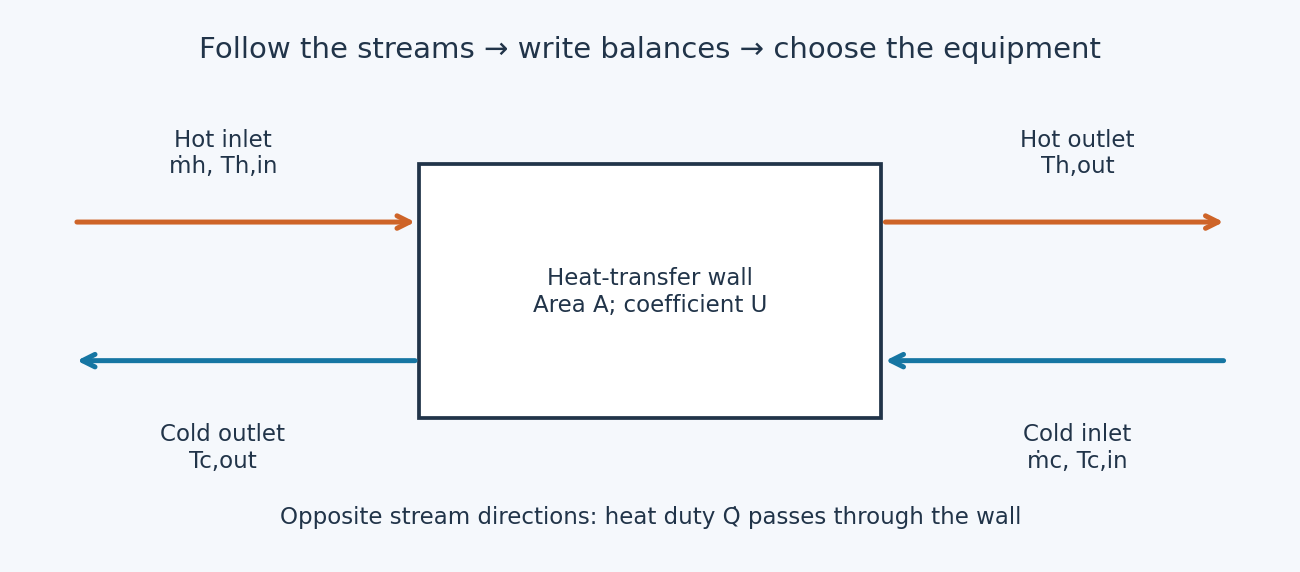

Schematic only: equipment sizes, heights and pipe lengths are not to scale.
Trace each stream with your finger. Identify what enters, what leaves, and where
energy is added or removed. Match the labels to the variables in the model below.

## Model and assumptions

Steady operation, no heat loss or phase change, constant heat capacities and overall
heat-transfer coefficient; ideal countercurrent flow, so the LMTD correction factor is 1.
For the main case, assume the clean overall coefficient is
$U_{clean}=650$ W/(m² K), based on heat-transfer area. It is a supplied
teaching value, not inferred from the inlet temperatures. Added fouling
resistance is introduced explicitly in the design comparison.
$C_h=\dot m_hc_{p,h}$, $C_c=\dot m_cc_{p,c}$, and
$\dot Q=C_h(T_{h,in}-T_{h,out})=C_c(T_{c,out}-T_{c,in})$.
$\Delta T_1=T_{h,in}-T_{c,out}$, $\Delta T_2=T_{h,out}-T_{c,in}$.
$\Delta T_{lm}=(\Delta T_1-\Delta T_2)/\ln(\Delta T_1/\Delta T_2)$ and
$A=\dot Q/(U\Delta T_{lm})$. Both terminal differences must be positive.
For a fixed area use effectiveness–NTU to predict new outlets, rather than keeping
the design duty fixed. Resistances below refer to the same heat-transfer area.

### Main-case input reference

These supplied synthetic inputs define the main case, not the smaller example.

| Input | Value / units | Role |
| --- | --- | --- |
| Hot / cold mass flow | 1.2 / 1.0 kg/s | Given process flow / water delivery |
| Hot specific heat capacity | 3800 J/(kg K) | Constant assumed process-fluid property |
| Cold specific heat capacity | 4180 J/(kg K) | Constant assumed water property |
| Hot / cold inlet temperature | 85 / 15 °C | Given inlet conditions |
| Cold outlet temperature | 55 °C | Required target |
| Clean overall coefficient Uclean | 650 W/(m² K) | Assumed clean performance on the stated heat-transfer area basis |
| LMTD correction factor | 1, dimensionless | Ideal countercurrent geometry |

Capacity rates Ch and Cc (W/K), duty (W), hot outlet (°C), LMTD (K) and
area (m²) are calculated. Specific heat capacity cp differs from capacity rate
C = mass flow × cp. Fouling, cost, area alternatives and operating hours are
separate supplied inputs in later sections. No property lookup is implied.

### Worked example: heat a small cold-water stream
Trace the orange stream left to right and the blue stream right to left.
Use an easier target first: heat 0.5 kg/s of water from 15 to 35 °C using
1.0 kg/s of hot water entering at 70 °C. Both **specific heat capacities**
are assumed constant at 4180 J/(kg K). The heat-capacity rates C = mass flow × cp
are different: 4180 W/K hot and 2090 W/K cold.

**Assume an overall heat-transfer coefficient U = 650 W/(m² K)** for this
clean, ideal countercurrent exchanger. It represents the combined fluid-film
and wall resistance on the stated area basis; it is a supplied teaching
assumption, not calculated from the terminal temperatures or measured equipment.
There is no additional fouling, heat loss or phase change in this example.

| Supplied example input | Value / units | Status |
| --- | --- | --- |
| Hot / cold mass flow | 1.0 / 0.5 kg/s | Given example conditions |
| Both specific heat capacities | 4180 J/(kg K) | Constant assumed liquid properties |
| Hot inlet / cold inlet | 70 / 15 °C | Given inlet conditions |
| Cold outlet | 35 °C | Required target |
| Overall coefficient U | 650 W/(m² K) | Assumed clean exchanger performance |
| LMTD correction factor | 1, dimensionless | Ideal countercurrent geometry |

Duty, hot outlet, LMTD and area are **calculated outputs**. Temperature differences
have the same numerical value in K and °C. This smaller worked case is separate
from the main design case below; do not mix their stream data.
First calculate the duty, then use that same duty to calculate the hot outlet.
Only then calculate area. Expected results: 41.8 kW, 60 °C, and about 1.62 m².

In [3]:
ex_mh, ex_mc = 1.0, 0.5  # given hot/cold mass flows, kg/s
ex_cp = 4180.0  # assumed specific heat capacity of both liquids, J/(kg K)
ex_U = 650.0  # assumed clean overall heat-transfer coefficient, W/(m² K)
ex_Ch, ex_Cc = ex_mh * ex_cp, ex_mc * ex_cp  # capacity rates, W/K
ex_Thi, ex_Tci, ex_Tco = 70.0, 15.0, 35.0
ex_duty = ex_Cc * (ex_Tco - ex_Tci)
ex_Tho = ex_Thi - ex_duty / ex_Ch
ex_dt1, ex_dt2 = ex_Thi - ex_Tco, ex_Tho - ex_Tci
ex_lmtd = h.lmtd(ex_dt1, ex_dt2)
ex_area = ex_duty / (ex_U * ex_lmtd)
print(f"Duty = {ex_duty/1000:.1f} kW; hot outlet = {ex_Tho:.1f} °C")
print(f"Terminal differences = {ex_dt1:.1f}, {ex_dt2:.1f} K; LMTD = {ex_lmtd:.2f} K")
print(f"Required area = {ex_area:.2f} m²")
print("Energy-balance residual / W:", ex_Ch*(ex_Thi-ex_Tho)-ex_duty)

Duty = 41.8 kW; hot outlet = 60.0 °C
Terminal differences = 35.0, 45.0 K; LMTD = 39.79 K
Required area = 1.62 m²
Energy-balance residual / W: 0.0


**Try a small change:** Copy the cell and raise the cold outlet target to 45 °C. Predict whether area rises or falls. Then try 75 °C: inspect both terminal differences and explain why this target fails before asking the helper to evaluate LMTD.

Spend about 20 minutes on this example within the model-development time below. Predict → run → explain. Then move to the main case.

### Solution to the small change

Raising the cold outlet target increases both duty and required area. A 75 °C target exceeds the 70 °C hot inlet and gives a negative terminal driving force, so it is infeasible for this passive exchanger.

In [4]:
for warm_target in [35., 45., 75.]:
    warm_duty = ex_Cc*(warm_target-ex_Tci)
    warm_hot_out = ex_Thi-warm_duty/ex_Ch
    warm_deltas = (ex_Thi-warm_target, warm_hot_out-ex_Tci)
    if min(warm_deltas) <= 0:
        print(f"Target {warm_target:.0f} °C: infeasible; terminal differences = {warm_deltas}")
    else:
        warm_area = warm_duty/(ex_U*h.lmtd(*warm_deltas))
        print(f"Target {warm_target:.0f} °C: duty {warm_duty/1000:.2f} kW, area {warm_area:.3f} m²")

Target 35 °C: duty 41.80 kW, area 1.616 m²
Target 45 °C: duty 62.70 kW, area 3.022 m²
Target 75 °C: infeasible; terminal differences = (-5.0, 25.0)


### Main design case

The next cell defines the larger case used in the assessed tasks. Example variables use `ex_` so you can rerun them without changing this case.

In [5]:
mh, mc = 1.2, 1.0  # kg/s
cph, cpc = 3800.0, 4180.0  # J/(kg K)
Thi, Tci, Tco_target = 85.0, 15.0, 55.0  # °C; differences are K
Ch, Cc = mh*cph, mc*cpc
U_clean = 650.0  # W/(m² K), assumed
duty = Cc * (Tco_target - Tci)
Tho = Thi - duty / Ch
delta_lm = h.lmtd(Thi-Tco_target, Tho-Tci)
area = duty / (U_clean * delta_lm)
print(f"Duty: {duty/1000:.1f} kW; hot outlet: {Tho:.2f} °C; area: {area:.2f} m²")

Duty: 167.2 kW; hot outlet: 48.33 °C; area: 8.13 m²


## 2. Check that the temperature target is feasible — 75 minutes

Run the supplied balance and temperature schematic. Check one duty
calculation with a calculator. Locate both terminal driving forces on the system
diagram. Is the target duty below the thermodynamic maximum? Explain why the
cold outlet may exceed the hot outlet without reversing local heat flow. Identify
the stream data you would measure to check this design in an operating plant.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

Duty = 167.200 kW; hot outlet = 48.3333 °C
Area = 8.13059 m²; Qmax = 292.600 kW; effectiveness = 0.571429
Balance residual = 0.000e+00 W; terminal differences = 30.000, 33.333 K


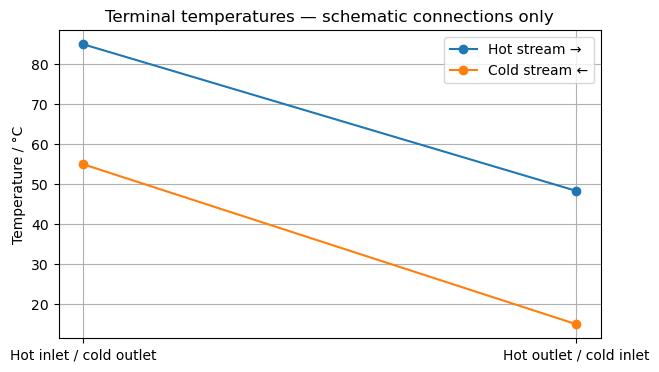

In [6]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
cold_duty = mc*cpc*(Tco_target-Tci)
independent_hot_out = Thi-cold_duty/(mh*cph)
dt1, dt2 = Thi-Tco_target, independent_hot_out-Tci
independent_lmtd = (dt1-dt2)/np.log(dt1/dt2)
independent_area = cold_duty/(U_clean*independent_lmtd)
qmax = min(Ch, Cc)*(Thi-Tci)
effectiveness = cold_duty/qmax
energy_residual = Ch*(Thi-independent_hot_out)-cold_duty
assert np.isclose(independent_area, area)
assert abs(energy_residual) < 1e-8
print(f"Duty = {cold_duty/1000:.3f} kW; hot outlet = {independent_hot_out:.4f} °C")
print(f"Area = {independent_area:.5f} m²; Qmax = {qmax/1000:.3f} kW; effectiveness = {effectiveness:.6f}")
print(f"Balance residual = {energy_residual:.3e} W; terminal differences = {dt1:.3f}, {dt2:.3f} K")
plt.figure(figsize=(7,4))
plt.plot([0,1], [Thi, independent_hot_out], 'o-', label='Hot stream →')
plt.plot([0,1], [Tco_target, Tci], 'o-', label='Cold stream ←')
plt.xticks([0,1], ['Hot inlet / cold outlet', 'Hot outlet / cold inlet'])
plt.ylabel('Temperature / °C'); plt.title('Terminal temperatures — schematic connections only')
plt.legend(); plt.grid(); plt.show()

**Answers to the design questions — default settings**


**Hand check and energy balance.** The cold stream requires
$1.0\times4180\times(55-15)=167200$ W, or 167.2 kW. The hot capacity
rate is $1.2\times3800=4560$ W/K, giving a hot outlet of
$85-167200/4560=48.3333$ °C. The hot and cold duties agree.

**Where are the driving forces?** At the hot-inlet/cold-outlet end,
$\Delta T_1=85-55=30$ K. At the hot-outlet/cold-inlet end,
$\Delta T_2=48.3333-15=33.3333$ K. Both are positive. The maximum duty is
$\min(4560,4180)(85-15)=292.6$ kW, so the target is feasible in the
ideal model and uses 57.14% of this maximum.

**Why can the outlets cross?** The 55 °C cold outlet and 48.3333 °C hot
outlet are at opposite ends. The hot stream remains warmer than the adjacent
cold stream at each terminal location. Comparing the two outlet temperatures
alone is not a test of local heat-transfer direction. The connecting lines
in the temperature figure are schematic, not calculated profiles.

**Plant measurements.** Measure both mass flows, all four temperatures,
stream compositions and relevant heat capacities. Record uncertainties and
steady-state conditions so the two duties can be compared meaningfully.
Check ambient losses and changes in inventory before attributing a duty
imbalance to the exchanger itself.

## 3. Review the thermal design checks — 90 minutes

Run the supplied effectiveness–NTU verification. Compare its outlet
temperatures with the LMTD design. Explain the zero-transfer and large-area
limits in physical terms. Do the agreement and limiting-case checks establish
that the real exchanger will work? Identify at least two assumptions that still
need confirmation. Choose whether this design is ready for thermal review,
hydraulic review or purchase, and justify that decision.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [7]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
def effectiveness_own(ntu, cr):
    if ntu < 0 or not 0 <= cr <= 1:
        raise ValueError("Require NTU >= 0 and 0 <= Cr <= 1")
    if abs(1-cr) < 1e-10:
        return ntu/(1+ntu)
    numerator = -np.expm1(-ntu*(1-cr))
    return numerator/((1-cr)+cr*numerator)

def predict_outlets(UA, hot_capacity=Ch, cold_capacity=Cc):
    cmin, cmax = min(hot_capacity, cold_capacity), max(hot_capacity, cold_capacity)
    eps = effectiveness_own(UA/cmin, cmin/cmax)
    q = eps*cmin*(Thi-Tci)
    return Thi-q/hot_capacity, Tci+q/cold_capacity, q

ntu, cr = U_clean*area/min(Ch,Cc), min(Ch,Cc)/max(Ch,Cc)
recovered_hot, recovered_cold, recovered_duty = predict_outlets(U_clean*area)
assert np.allclose([recovered_hot, recovered_cold, recovered_duty], [Tho,Tco_target,duty])
assert np.isclose(effectiveness_own(2,1), 2/3)
assert np.isclose(effectiveness_own(1e-9,.5), 1e-9, rtol=1e-6, atol=1e-15)
assert np.isclose(effectiveness_own(100,.5), 1)
assert np.isclose(effectiveness_own(0,.5), 0)
for test_ntu in [0, 1e-9, 1, 100]:
    for test_cr in [.5, 1.0]:
        assert np.isclose(effectiveness_own(test_ntu,test_cr), h.countercurrent_effectiveness(test_ntu,test_cr))
print(f"NTU = {ntu:.6f}; Cr = {cr:.6f}; hot outlet = {recovered_hot:.4f} °C; cold outlet = {recovered_cold:.4f} °C")
print("Zero, small/large NTU, equal-capacity and helper comparisons passed")

NTU = 1.264326; Cr = 0.916667; hot outlet = 48.3333 °C; cold outlet = 55.0000 °C
Zero, small/large NTU, equal-capacity and helper comparisons passed


**Answers to the design questions — default settings**


**Agreement of methods.** The supplied effectiveness–NTU calculation gives
the same 55 °C cold outlet, 48.3333 °C hot outlet and 167.2 kW duty as
the LMTD calculation at 8.13059 m² clean area. NTU is about 1.2643 and
the capacity ratio is about 0.9167.

**Physical limiting cases.** At zero UA or zero area, there is no heat
transfer: both streams leave at their inlet temperatures. With increasingly
large UA, effectiveness tends to one; the smaller-capacity stream approaches
the other stream's inlet temperature. A finite, ideal exchanger cannot
exceed the maximum duty. For equal capacity rates the analytical expression
must use its limit, $\varepsilon=NTU/(1+NTU)$.

**What do the checks prove?** Agreement and limiting cases support the
implementation and internal consistency of the ideal thermal model. They
do not prove actual equipment performance. Confirm U at the actual velocities,
temperature-dependent properties, fouling behaviour, external heat losses,
flow distribution and whether the geometry is truly countercurrent.

**Readiness decision.** I would submit the calculation for thermal review
and proceed to hydraulic/geometric design, not purchase. Allowable pressure
drop, channel dimensions, pumping power and mechanical requirements have
not been checked. A model can pass thermal verification while describing
equipment that is impractical or hydraulically unsuitable.

## 4. Choose a fouling allowance and installed area — 75 minutes

Choose an added fouling resistance in the settings cell. Read the
fixed-area performance curves and compare a clean-sized unit with an enlarged
unit designed to meet the target at your chosen resistance. Report the added
area percentage. Would you specify the larger area or accept a lower outlet
temperature between cleanings? State the process requirement supporting your
choice. What happens when the enlarged exchanger is clean, and what control
action would be needed?

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

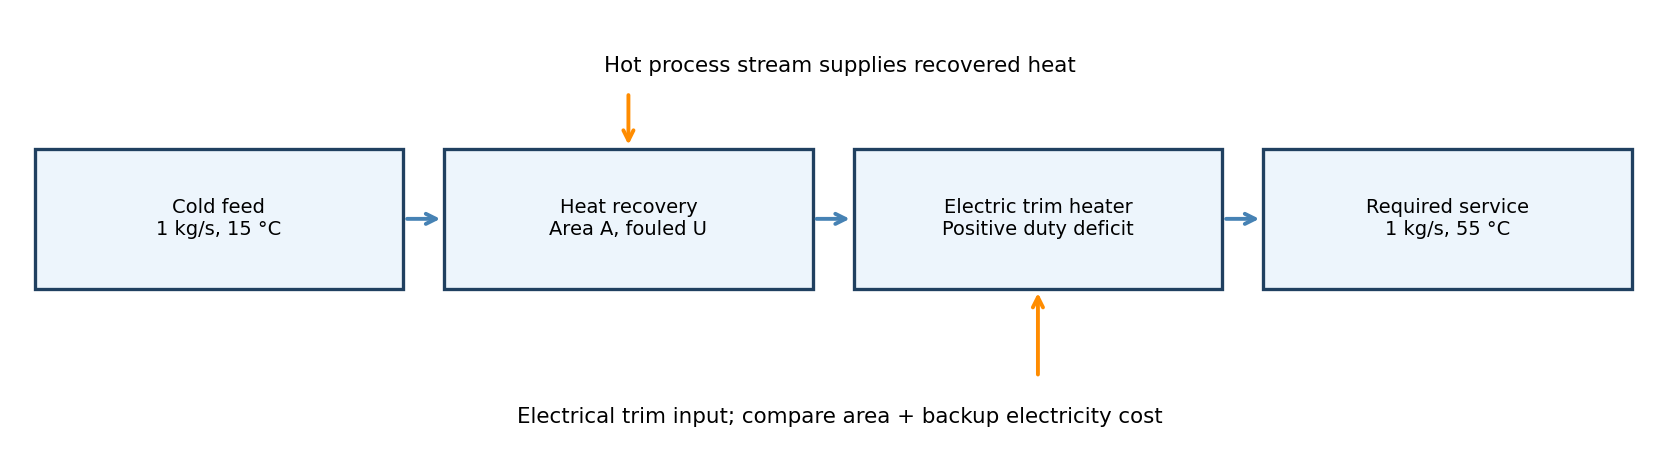

Block diagram of the design boundary; see the main flowsheet for physical stream connections.


**Core design challenge — recover heat, then supply any deficit.** The system
is now an exchanger followed by a trim heater, delivering the same **1 kg/s
at 55 °C** for 4000 h/year. Compare supplied areas 8.13059, 11.30152 and
14 m² at your chosen fouling resistance. The trim heater supplies only the
positive deficit to 167.2 kW, at assumed efficiency one. Excess recovered heat
gets no sale credit; bypass/control would be needed to hold the target.

Illustrative installed exchanger cost is **€4000 + €700 per m²**. Compare
installed cost plus ten years of trim-heater electricity at €0.10/kWh.
Heater capital, hydraulic power, maintenance, cleaning and discounting are
omitted. These are supplied teaching prices, not quotations.

Choose an area, report recovered heat, backup power, annual backup electricity
and total modelled cost. Does your choice change at zero added resistance or
at 0.001 m² K/W? Is the cheapest exchanger also the cheapest way to deliver
the required service? A larger exchanger is not automatically sufficient at
every fouling condition. Explain the control and cleaning assumptions.


In [8]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# m² K/W; choose between 0 and 0.001
design_R = 0.0006 #@param {type:"number"}
trim_electricity_price = 0.10 #@param {type:"number"}
cost_horizon = 10 #@param {type:"number"}

At design fouling: U=467.626 W/(m² K)
Clean-sized area=8.1306 m²: Tco=49.0093 °C, duty=142.159 kW
Fouling-sized area=11.3015 m²: Tco=55.0000 °C
When clean, enlarged unit gives Tco=60.8005 °C: allow for control


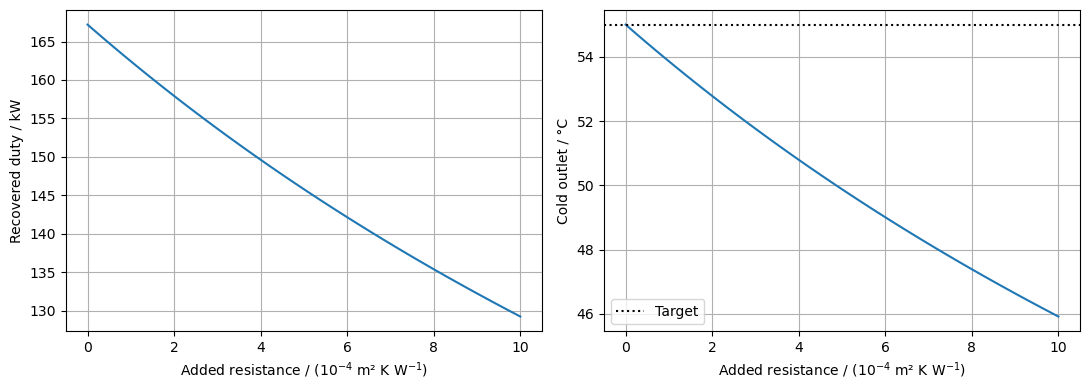

Area increase: 39.0%
Area/m²  recovery/kW  trim/kW   trim/kWh/year  capital/€  horizon/€
  8.131     142.159   25.041       100164.2     9691.4   109855.6
 11.302     167.200    0.000            0.0    11911.1    11911.1
 14.000     183.136    0.000            0.0    13800.0    13800.0
Least modelled service cost at selected fouling: 11.302 m²
R_f=0.0000: preferred area 8.131 m²; backup 0.000 kW
R_f=0.0006: preferred area 11.302 m²; backup 0.000 kW
R_f=0.0010: preferred area 14.000 m²; backup 0.000 kW


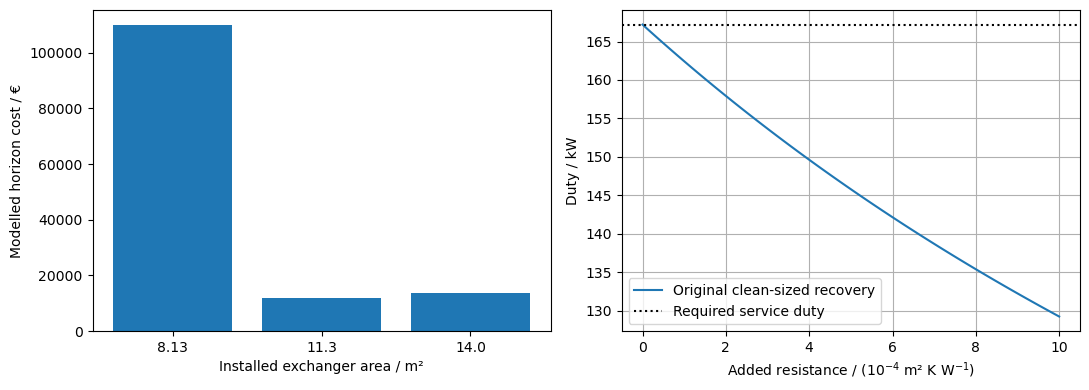

In [9]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
resistance = np.unique(np.r_[np.linspace(0,.001,60), .0006])
fouled_U = 1/(1/U_clean+resistance)
fixed_area_results = np.array([h.outlets(u*area, Ch, Cc, Thi, Tci) for u in fouled_U])
design_U = 1/(1/U_clean+design_R)
fouled_sized_area = duty/(design_U*delta_lm)
at_design = h.outlets(design_U*area, Ch,Cc,Thi,Tci)
enlarged_design = h.outlets(design_U*fouled_sized_area, Ch,Cc,Thi,Tci)
enlarged_clean = h.outlets(U_clean*fouled_sized_area, Ch,Cc,Thi,Tci)
assert np.isclose(enlarged_design[1],Tco_target)
print(f"At design fouling: U={design_U:.3f} W/(m² K)")
print(f"Clean-sized area={area:.4f} m²: Tco={at_design[1]:.4f} °C, duty={at_design[2]/1000:.3f} kW")
print(f"Fouling-sized area={fouled_sized_area:.4f} m²: Tco={enlarged_design[1]:.4f} °C")
print(f"When clean, enlarged unit gives Tco={enlarged_clean[1]:.4f} °C: allow for control")
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(resistance*1e4, fixed_area_results[:,2]/1000)
axes[0].set_ylabel('Recovered duty / kW')
axes[1].plot(resistance*1e4, fixed_area_results[:,1])
axes[1].axhline(55,color='black',linestyle=':', label='Target'); axes[1].legend()
axes[1].set_ylabel('Cold outlet / °C')
for axis in axes:
    axis.set_xlabel('Added resistance / (10$^{-4}$ m² K W$^{-1}$)'); axis.grid()
plt.tight_layout(); plt.show()
print(f"Area increase: {(fouled_sized_area/area-1)*100:.1f}%")


# Same-service area/backup-heating comparison.
heat_designs = h.compare_designs(design_R,trim_electricity_price,cost_horizon)
print('Area/m²  recovery/kW  trim/kW   trim/kWh/year  capital/€  horizon/€')
for row in heat_designs:
    print(f"{row['area']:7.3f} {row['recovery_kw']:11.3f} {row['trim_kw']:8.3f} {row['annual_kwh']:14.1f} {row['installed']:10.1f} {row['total']:10.1f}")
heat_best = min(heat_designs,key=lambda row:row['total'])
installed_area = heat_best['area']
print(f"Least modelled service cost at selected fouling: {heat_best['area']:.3f} m²")
for test_resistance in [0.,.0006,.001]:
    candidates = h.compare_designs(test_resistance,trim_electricity_price,cost_horizon)
    best = min(candidates,key=lambda row:row['total'])
    print(f"R_f={test_resistance:.4f}: preferred area {best['area']:.3f} m²; backup {best['trim_kw']:.3f} kW")
fig,axes = plt.subplots(1,2,figsize=(11,4))
axes[0].bar([str(round(r['area'],2)) for r in heat_designs],[r['total'] for r in heat_designs])
axes[0].set(xlabel='Installed exchanger area / m²',ylabel='Modelled horizon cost / €')
axes[1].plot(resistance*1e4,fixed_area_results[:,2]/1000,label='Original clean-sized recovery')
axes[1].axhline(167.2,color='black',linestyle=':',label='Required service duty')
axes[1].set(xlabel='Added resistance / (10$^{-4}$ m² K W$^{-1}$)',ylabel='Duty / kW')
axes[1].legend(); axes[1].grid(); plt.tight_layout(); plt.show()


**Answers to the design questions — default settings**


**Chosen allowance and area.** I use the default added resistance
0.0006 m² K/W. It lowers U from 650 to about 467.63 W/(m² K).
The clean-sized area of 8.13059 m² then gives only 142.16 kW and a cold
outlet of 49.0093 °C. It cannot meet the stated 55 °C target.

**Added area percentage.** Retaining the target duty and terminal temperatures
requires 11.3015 m². Since thermal resistance increases by a factor
$1+650(0.0006)=1.39$, the required area increases by **39%**. The supplied
fixed-area curves instead let duty and outlets change as resistance grows;
these are different design questions.

**Decision and alternative.** If 55 °C at 1 kg/s is a process requirement
through the stated fouling condition, I would specify the enlarged thermal
area, subject to hydraulic review. Accepting 49 °C would violate that
requirement. A smaller unit could be defended only with an explicitly
permitted lower temperature, supplemental heating or a justified cleaning
policy; it is not an equivalent design by itself.

**Clean operation and control.** The enlarged exchanger gives about 60.80 °C
when clean at these flows. If 55 °C is an exact target, use suitable bypass
or temperature/flow control. Extra installed area is not automatically a
safe operating margin if excessive outlet temperature is undesirable.



**Core challenge: compare the same delivered service.** At the default fouling
resistance, the 8.13059 m² unit recovers 142.159 kW and needs 25.041 kW
of trim heating to supply the required 167.2 kW service. At 4000 h/year,
that is about 100164 kWh/year of backup electricity. The 11.30152 m² unit
recovers essentially the full target duty and needs no meaningful trim heat;
the microscopic printed deficit is rounding of the supplied area. The 14 m²
unit can recover about 183.136 kW, more than the required service, and needs
control/bypass rather than a fictitious negative heater demand.

**Choice and rejection.** At €0.10/kWh over ten years, the respective
exchanger-plus-backup totals are approximately €109856, €11911 and €13800.
I choose 11.30152 m² for the stated default fouling condition. The cheapest
exchanger to install, 8.13059 m², is far from the cheapest way to provide
the same delivered service once its heat deficit is supplied electrically.
The 14 m² option adds cost without a credited benefit under this duty.

**Changed condition.** With zero added resistance, the smallest exchanger
already supplies the target and is cheapest. At resistance 0.001 m² K/W,
14 m² becomes the preferred supplied candidate. Thus the fouling allowance
and cleaning policy can change the equipment choice. This model omits backup
heater purchase cost, exchanger pumping power, cleaning costs and discounting;
its ranking is conditional on those omissions and the stated control assumptions.

## 5. Define an operating envelope — 45 minutes

Take a 10-minute break. Use the supplied cold-flow sweep at fixed
chosen area and fouling allowance. Identify which tested flows meet the 55 °C
target, and select an operating flow or range. Explain the difference between
maximizing heat recovery and maximizing outlet temperature. What further
pressure-drop and pumping calculations must accompany your thermal decision?
State why the constant-U sweep is provisional.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [10]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# kg/s
cold_flow_low = 0.5 #@param {type:"number"}
# kg/s
cold_flow_high = 1.8 #@param {type:"number"}

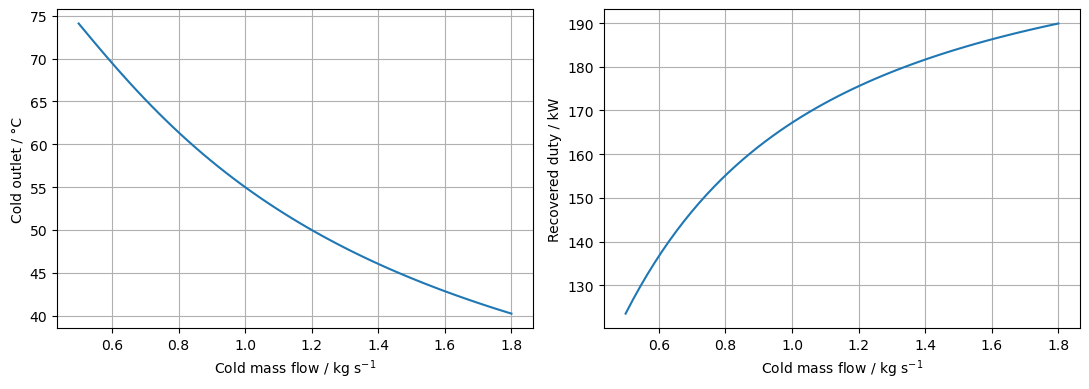

mc=0.50 kg/s: Tco=74.091 °C, duty=123.501 kW
mc=1.80 kg/s: Tco=40.240 °C, duty=189.909 kW
Tested flows meeting target: 0.500–1.000 kg/s


In [11]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
cold_flows = np.unique(np.r_[np.linspace(cold_flow_low,cold_flow_high,60),mc])
# Chosen design: fouling-sized area, operated at design fouling resistance.
flow_results = np.array([h.outlets(design_U*installed_area,Ch,value*cpc,Thi,Tci)
                         for value in cold_flows])
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(cold_flows,flow_results[:,1]); axes[0].set_ylabel('Cold outlet / °C')
axes[1].plot(cold_flows,flow_results[:,2]/1000); axes[1].set_ylabel('Recovered duty / kW')
for axis in axes:
    axis.set_xlabel('Cold mass flow / kg s$^{-1}$'); axis.grid()
plt.tight_layout(); plt.show()
for index in [0,-1]:
    print(f"mc={cold_flows[index]:.2f} kg/s: Tco={flow_results[index,1]:.3f} °C, duty={flow_results[index,2]/1000:.3f} kW")
assert np.allclose(Ch*(Thi-flow_results[:,0]), cold_flows*cpc*(flow_results[:,1]-Tci))
meets_target = flow_results[:,1] >= Tco_target-1e-8
if np.any(meets_target):
    qualifying = cold_flows[meets_target]
    print(f"Tested flows meeting target: {qualifying.min():.3f}–{qualifying.max():.3f} kg/s")
else:
    print("No tested flow meets the outlet-temperature target")

**Answers to the design questions — default settings**


**Qualifying tested flows.** At the chosen fouling-sized area and design
resistance, the sweep meets at least 55 °C for tested cold flows from
0.5 through 1.0 kg/s. The explicitly included 1.0 kg/s point gives exactly
55 °C. Higher tested flows fall below target. This is a sampled thermal
envelope under fixed U, not a certified continuous operating range.

**Selected operating policy.** I retain 1.0 kg/s as the nominal design flow
because it meets the original throughput and temperature requirement.
Lower flows give hotter water but deliver less water and less total heat;
they should not be presented as equivalent ways to meet a 1 kg/s duty.
The nominal point has no temperature margin at the specified design fouling,
so control, cleaning or an additional justified allowance deserves review.

**Heat recovery versus temperature.** At 0.5 kg/s the model gives about
74.09 °C and 123.50 kW; at 1.8 kg/s it gives 40.24 °C and 189.91 kW.
More recovered heat does not guarantee a useful delivery temperature.

**Missing hydraulic work.** Establish channel/tube geometry, velocities,
Reynolds numbers, pressure drop, pump duty and allowable mechanical loads.
U generally changes with flow through convection coefficients; heat losses
and fouling can also vary. These omissions make the constant-U envelope
provisional even though its energy balances close.

## 6. Engineering recommendation and submission — 45 minutes
Choose a design and support it with numbers. State what would need measuring before
using it in practice. Check your balances and inspect every axis label and unit.
Restart the kernel and run all completed cells in order before submission.

**Peer check:** Ask your partner to explain one equation, one numerical check,
and one reason the model could fail. Record any revision this discussion prompted.

**Design-review checklist:** Does your selected design meet every stated
requirement? Include its operating margin, one rejected alternative and a
numerical reason for rejection. Distinguish a model verification check from
evidence that real equipment will perform as predicted. Identify the next
measurement or vendor datum needed. No new code is required for submission.

Include your choice from the core cost/constraint table, a rejected alternative and the effect of the changed duty or adverse condition. Identify both the energy/circulation criterion and the cost criterion.

### Example engineering recommendation

For the default fouling allowance, I recommend carrying forward
an exchanger of about 11.30152 m², delivering 1 kg/s water at 55 °C with
negligible normal trim heating at that condition. The supplied comparison gives
about €11911 over ten years for exchanger installation plus backup electricity,
compared with about €109856 for the clean-sized unit with continuous trim heat.
This is a same-service comparison, not simply a comparison of recovered kilowatts.
At a larger fouling allowance of 0.001 m² K/W, I would review the 14 m²
candidate instead. The following thermal checks refer to the default case.

At the specified flows, the target duty is 167.2 kW. Conservation of energy
then gives a hot outlet of 48.3333 °C. The two terminal driving forces are
positive, and the required duty is only 57.14% of the thermodynamic maximum.
These checks establish feasibility within the ideal model. The cold outlet
being warmer than the hot outlet does not violate heat-transfer direction:
the outlets are at opposite ends of the countercurrent exchanger.

A clean-only design needs 8.13059 m². The independently implemented
effectiveness–NTU method reproduces the LMTD result, including both outlet
temperatures, and passes checks at zero NTU, large NTU and equal capacity
rates. With the clean-sized area held fixed, the design fouling resistance
reduces the cold outlet to about 49.01 °C. Adding area instead restores the
target. The enlarged unit will recover more heat when clean, so temperature
control or bypass provision should accompany the area allowance.

The cold-flow sweep shows that maximum heat recovery and maximum outlet
temperature are different objectives. Increasing cold flow can increase total
duty while lowering its outlet temperature. Operation should therefore be
judged against both process heat demand and the required temperature level,
not against recovered kilowatts alone.

Before purchase, confirm physical properties over the temperature range,
fouling behaviour, cleaning intervals, allowable pressure drops and actual
heat-transfer geometry. Flow-dependent convection coefficients and pumping
power are absent from this model, and a real multipass exchanger may need
an LMTD correction. Collect calibrated inlet/outlet temperatures and both
mass flows during operation to verify the energy balance and estimate UA.
Use those measurements to revise the fouling allowance and maintenance
schedule rather than treating the assumed resistance as a measured fact.

**Review note:** This is an instructor model answer. The checks below document a self-review; no student peer discussion or real equipment validation is claimed.

## Optional design-review extension

No coding is required. Would a low cold outlet necessarily prove fouling? Propose measurements that distinguish heat loss to the room from reduced UA.